
Positive Common Words:
Word/Phrase  Count
       nice     92
      looks     67
        fit     59
       good     59
    quality     59
     fabric     59
      money     36
      value     36
      happy     35
   purchase     35

Negative Common Words:
Word/Phrase  Count
     fabric     18
     better     15
   expected     15
     decent     15
       fine     11
        fit     11
      daily     11
        use     11
      loose     10
    quality     10


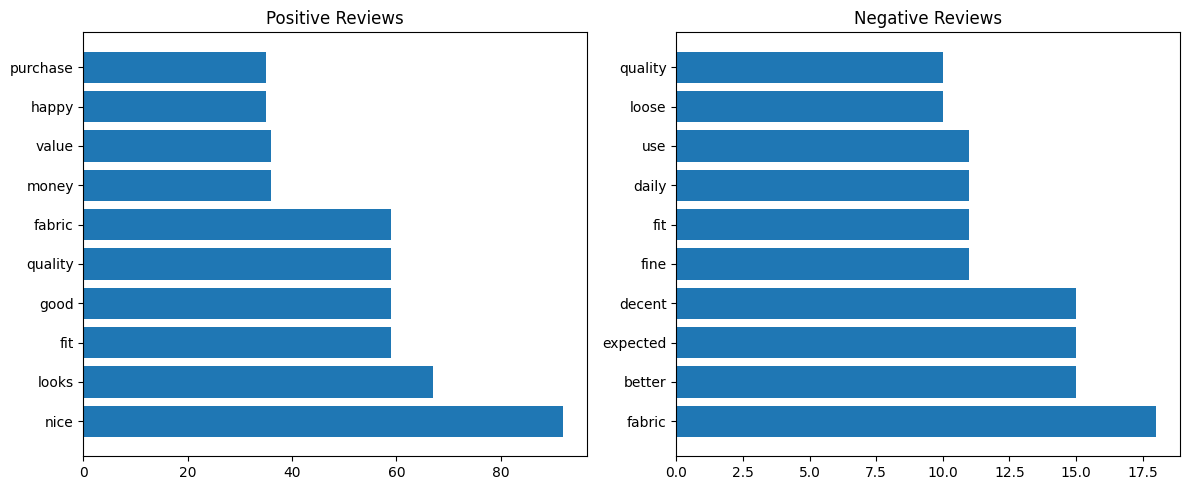


Positive Bigrams:
    Word/Phrase  Count
    value money     36
 happy purchase     35
     nice happy     35
     looks nice     35
   looks better     32
  better photos     32
got compliments     31
      fit great     30
    color shown     30
    perfect fit     30

Negative Bigrams:
    Word/Phrase  Count
  better fabric     15
expected better     15
decent expected     15
      daily use     11
     fine daily     11
     fit little     10
   little loose     10
   okay special      8
average quality      6
     faded wash      6

Positive Trigrams:
        Word/Phrase  Count
nice happy purchase     35
   looks nice happy     35
looks better photos     32
   good color shown     30
  fabric good color     30
  fit great quality     30
  perfect fit great     30
 feels soft premium     29
  fabric feels soft     29
  good quality nice     29

Negative Trigrams:
             Word/Phrase  Count
  expected better fabric     15
  decent expected better     15
          fine daily us

In [1]:

# 1. Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import re
from sklearn.feature_extraction.text import CountVectorizer
from gensim.models import Word2Vec

# 2. Load dataset
df = pd.read_csv("../dataset/womens_clothing_analysis.csv")

# 3. Prepare positive and negative reviews
df = df.dropna(subset=["Review", "Rating"])

positive = df[df["Rating"] >= 4]["Review"].astype(str)
negative = df[df["Rating"] <= 3]["Review"].astype(str)

# 4. Clean reviews
def clean_text(text):
    return re.sub(r"[^a-z\s]", "", text.lower())

positive = positive.apply(clean_text)
negative = negative.apply(clean_text)

# 5. Find common words and n-grams
def find_ngrams(reviews, n):
    vectorizer = CountVectorizer(
        stop_words="english",
        ngram_range=(n, n)
    )

    matrix = vectorizer.fit_transform(reviews)

    result = pd.DataFrame({
        "Word/Phrase": vectorizer.get_feature_names_out(),
        "Count": matrix.sum(axis=0).A1
    })

    return result.sort_values(
        "Count", ascending=False
    ).head(10)

# 6. Common words in positive and negative reviews
positive_words = find_ngrams(positive, 1)
negative_words = find_ngrams(negative, 1)

print("\nPositive Common Words:")
print(positive_words.to_string(index=False))

print("\nNegative Common Words:")
print(negative_words.to_string(index=False))

# 7. Display charts
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].barh(
    positive_words["Word/Phrase"],
    positive_words["Count"]
)
axes[0].set_title("Positive Reviews")

axes[1].barh(
    negative_words["Word/Phrase"],
    negative_words["Count"]
)
axes[1].set_title("Negative Reviews")

plt.tight_layout()
plt.show()

# 8. Find bigrams and trigrams
print("\nPositive Bigrams:")
print(find_ngrams(positive, 2).to_string(index=False))

print("\nNegative Bigrams:")
print(find_ngrams(negative, 2).to_string(index=False))

print("\nPositive Trigrams:")
print(find_ngrams(positive, 3).to_string(index=False))

print("\nNegative Trigrams:")
print(find_ngrams(negative, 3).to_string(index=False))

# 9. Word2Vec analysis
all_reviews = pd.concat([positive, negative])

sentences = [
    review.split()
    for review in all_reviews
    if len(review.split()) > 1
]

model = Word2Vec(
    sentences,
    vector_size=50,
    window=3,
    min_count=2,
    workers=1,
    seed=42
)

word = "fit"

if word in model.wv:
    print("\nWords related to:", word)
    print(model.wv.most_similar(word, topn=5))
else:
    print("\nWord not found in Word2Vec vocabulary.")

print("\nAnalysis completed!")
